<a href="https://colab.research.google.com/github/fpv5026/FinalProjectDataAnalysis/blob/main/Occupation_CreditScore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Credit Score OpenAI GPT 20b

In [133]:
import os
print("Current working directory:", os.getcwd())


Current working directory: /content


In [134]:
import pandas as pd

typo_df = pd.read_csv('/content/erscountytypology2025edition.csv')
diff_df = pd.read_csv('/content/cs_merged_data_openai_gpt-oss-20b.csv')

print('read')


read


In [135]:
filt_df = typo_df[typo_df["Attribute"] == "Industry_Dependence_2025"]
filt_df.head()


,FIPStxt,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
6,1001,AL,Autauga County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
19,1003,AL,Baldwin County,1,Industry_Dependence_2025,5,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
32,1005,AL,Barbour County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
45,1007,AL,Bibb County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
58,1009,AL,Blount County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


In [136]:
print(filt_df.columns)
print(diff_df.columns)


Index(['FIPStxt', 'State', 'County_Name', 'Metro2023', 'Attribute', 'Value',
       'PublicationDate', 'Source'],
      dtype='object')
Index(['county_fips', 'county', 'estimate', 'credit_score', 'Difference'], dtype='object')


In [137]:
diff_df.head()

,county_fips,county,estimate,credit_score,Difference
0,1007,"Bibb County, AL",670.0,640.017483,29.982517
1,1011,"Bullock County, AL",660.0,623.504424,36.495576
2,1005,"Barbour County, AL",590.0,650.661562,-60.661562
3,1003,"Baldwin County, AL",725.0,667.065871,57.934129
4,1001,"Autauga County, AL",705.0,656.947200,48.052800


In [138]:
filt_df = filt_df.rename(columns={"FIPStxt": "county_fips"})

merged = diff_df.merge(filt_df, on="county_fips", how="left")

merged = merged.dropna(subset=["county"])

merged.head()

,county_fips,county,estimate,credit_score,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1007,"Bibb County, AL",670.0,640.017483,29.982517,AL,Bibb County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1011,"Bullock County, AL",660.0,623.504424,36.495576,AL,Bullock County,0.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1005,"Barbour County, AL",590.0,650.661562,-60.661562,AL,Barbour County,0.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1003,"Baldwin County, AL",725.0,667.065871,57.934129,AL,Baldwin County,1.0,Industry_Dependence_2025,5.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1001,"Autauga County, AL",705.0,656.947200,48.052800,AL,Autauga County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_1057/3230759982.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged, palette="coolwarm")


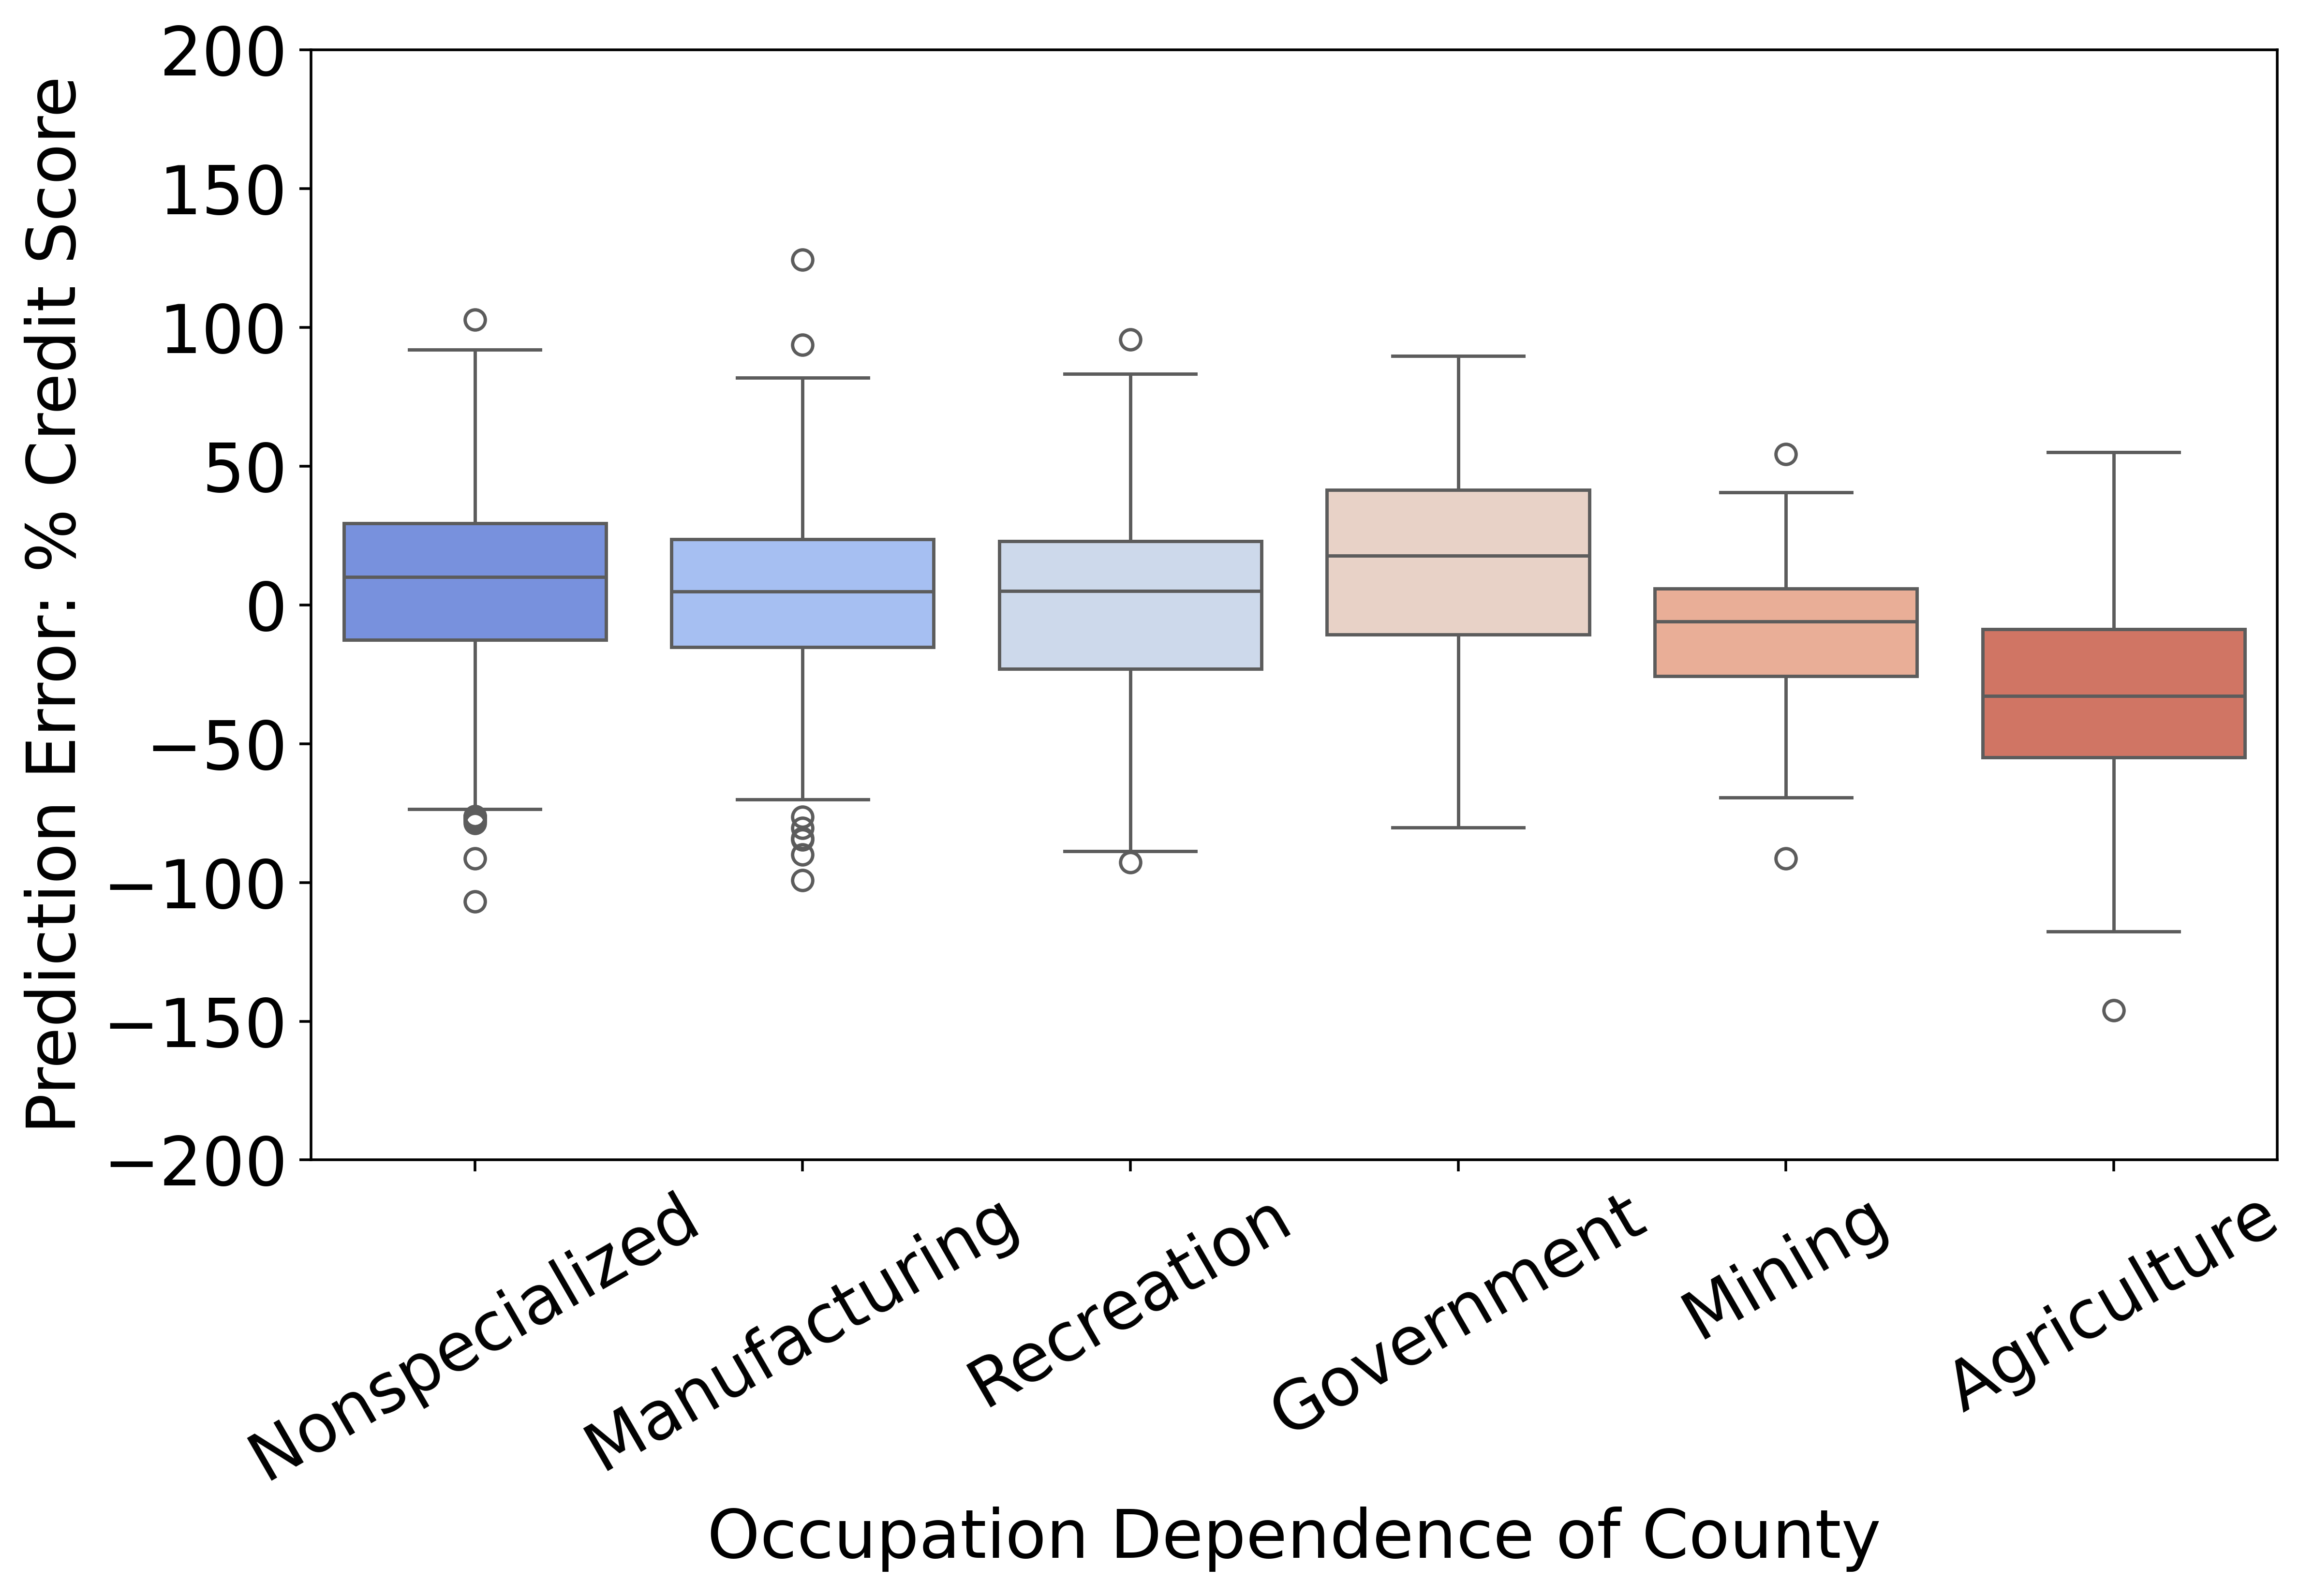

In [139]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged["OccupationType"] = merged["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % Credit Score')

plt.ylim(-200, 200)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [140]:
group_stats = merged.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture  -32.469471
1      Government   14.737860
2   Manufacturing    3.950779
3          Mining  -10.112102
4  Nonspecialized    8.644212
5      Recreation    0.979117


In [141]:
merged = merged.dropna(subset=["Value", "Difference"])
print(merged["Value"].value_counts(dropna=False))


Value
0.0    1577
3.0     706
1.0     354
5.0     265
4.0     146
2.0      89
Name: count, dtype: int64


In [142]:
from scipy.stats import f_oneway

occ_groups = [
    merged.loc[merged["Value"] == cat, "Difference"]
    for cat in sorted(merged["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 108.790, p-value: 0.0000


In [143]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged["Difference"],
    groups=merged["Value"],
    alpha=0.05
)
print(tukey)


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   0.0    1.0 -41.1137    0.0 -46.3481 -35.8792   True
   0.0    2.0 -18.7563    0.0  -28.453  -9.0596   True
   0.0    3.0  -4.6934 0.0117  -8.7237  -0.6632   True
   0.0    4.0   6.0936 0.2124  -1.6056  13.7929  False
   0.0    5.0  -7.6651  0.003 -13.5739  -1.7563   True
   1.0    2.0  22.3574    0.0  11.8037   32.911   True
   1.0    3.0  36.4202    0.0   30.624  42.2165   True
   1.0    4.0  47.2073    0.0  38.4534  55.9613   True
   1.0    5.0  33.4486    0.0  26.2189  40.6782   True
   2.0    3.0  14.0629 0.0009   4.0518   24.074   True
   2.0    4.0    24.85    0.0  12.8809   36.819   True
   2.0    5.0  11.0912 0.0435   0.1874  21.9951   True
   3.0    4.0  10.7871  0.002   2.6954  18.8787   True
   3.0    5.0  -2.9717 0.7731  -9.3835   3.4401  False
   4.0    5.0 -13.7587 0.0003 -22.9319  -4.5856   True
----------

#

#Credit Score OpenAI 120b

In [144]:
model2 = pd.read_csv('/content/cs_merged_data_openai_gpt-oss-120b.csv')

In [145]:
merged2 = model2.merge(filt_df, on="county_fips", how="left")

merged2 = merged2.dropna(subset=["county"])

merged2.head()

,county_fips,county,estimate,credit_score,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1009,"Blount County, AL",670.0,661.909095,8.090905,AL,Blount County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1007,"Bibb County, AL",660.0,640.017483,19.982517,AL,Bibb County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1013,"Butler County, AL",660.0,642.118493,17.881507,AL,Butler County,0.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1015,"Calhoun County, AL",660.0,653.576857,6.423143,AL,Calhoun County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1003,"Baldwin County, AL",710.0,667.065871,42.934129,AL,Baldwin County,1.0,Industry_Dependence_2025,5.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_1057/925944728.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged2, palette="coolwarm")


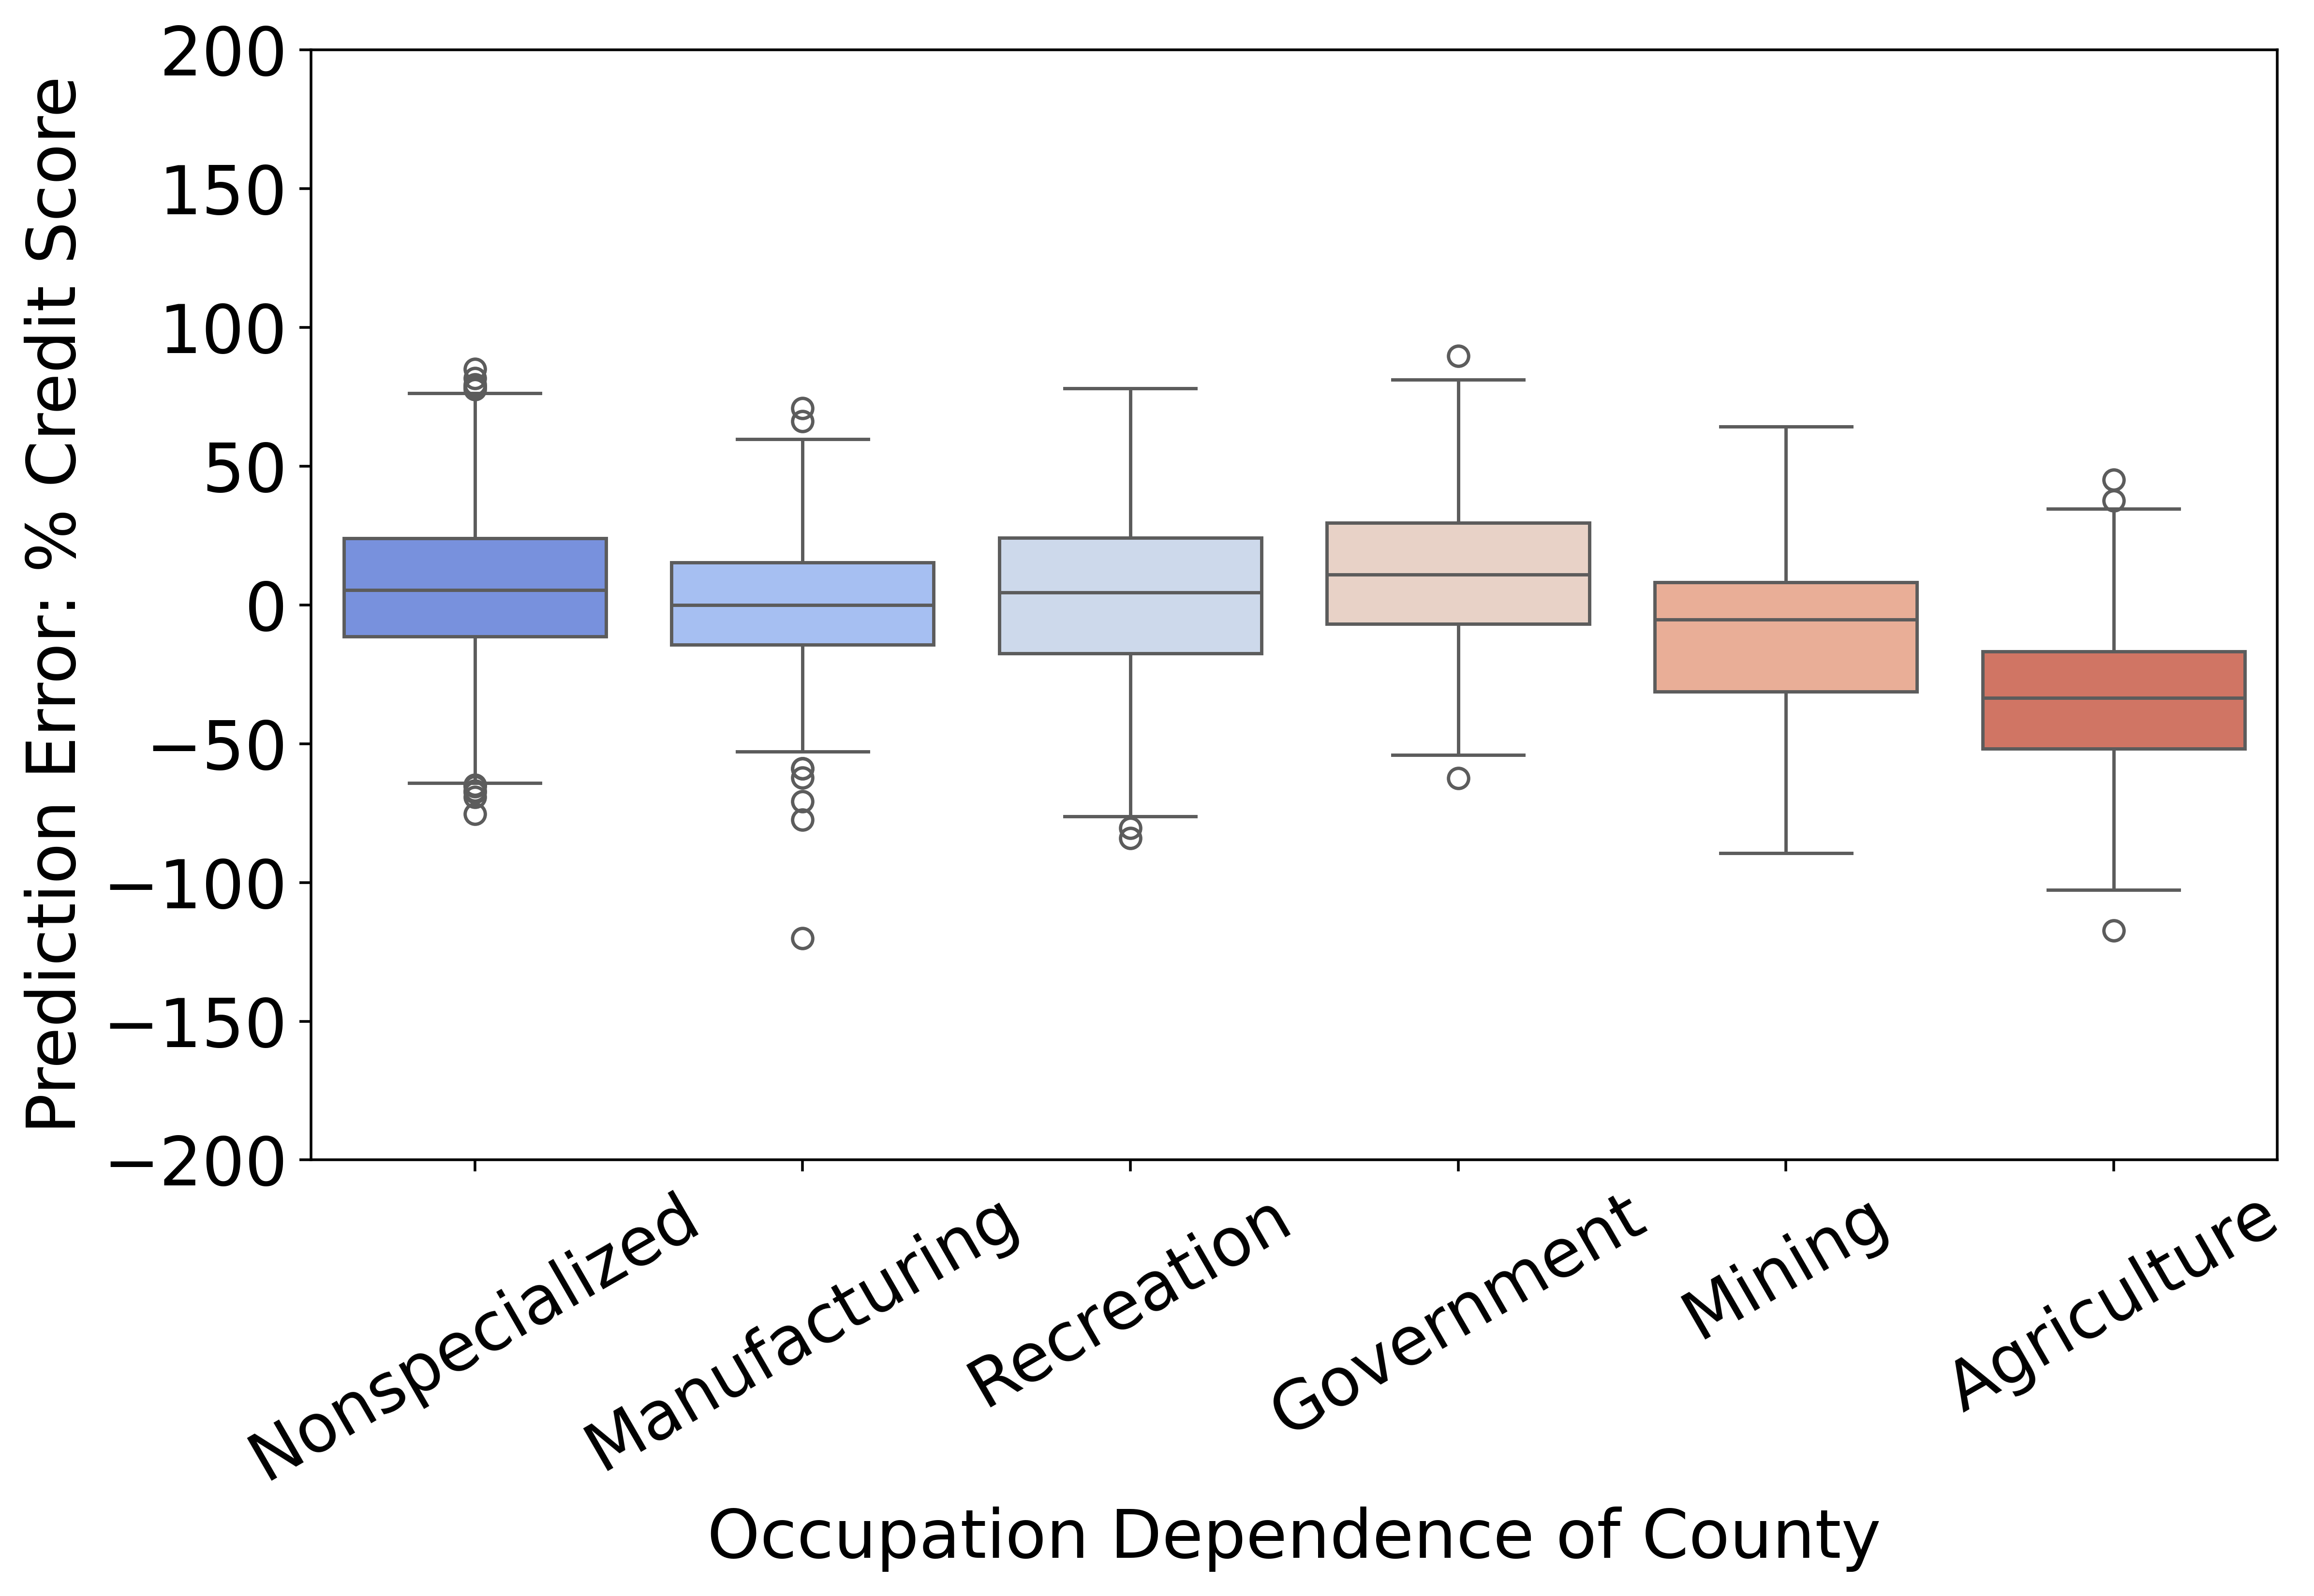

In [146]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged2["OccupationType"] = merged2["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged2, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % Credit Score')

plt.ylim(-200, 200)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [147]:
group_stats = merged2.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture  -33.172861
1      Government   11.094025
2   Manufacturing    0.086756
3          Mining   -8.157045
4  Nonspecialized    6.638505
5      Recreation    3.499872


In [148]:
merged2 = merged2.dropna(subset=["Value", "Difference"])
print(merged["Value"].value_counts(dropna=False))


Value
0.0    1577
3.0     706
1.0     354
5.0     265
4.0     146
2.0      89
Name: count, dtype: int64


In [149]:
from scipy.stats import f_oneway

occ_groups = [
    merged2.loc[merged2["Value"] == cat, "Difference"]
    for cat in sorted(merged2["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 143.532, p-value: 0.0000


In [150]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged2["Difference"],
    groups=merged2["Value"],
    alpha=0.05
)
print(tukey)


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   0.0    1.0 -39.8114    0.0 -44.1759 -35.4468   True
   0.0    2.0 -14.7956    0.0 -22.8807  -6.7104   True
   0.0    3.0  -6.5517    0.0  -9.9122  -3.1913   True
   0.0    4.0   4.4555 0.3546  -1.9642  10.8752  False
   0.0    5.0  -3.1386 0.4551  -8.0655   1.7882  False
   1.0    2.0  25.0158    0.0  16.2161  33.8155   True
   1.0    3.0  33.2596    0.0  28.4267  38.0926   True
   1.0    4.0  44.2669    0.0  36.9678   51.566   True
   1.0    5.0  36.6727    0.0  30.6446  42.7009   True
   2.0    3.0   8.2438 0.0552  -0.1036  16.5912  False
   2.0    4.0  19.2511    0.0   9.2712  29.2309   True
   2.0    5.0  11.6569 0.0035   2.5652  20.7486   True
   3.0    4.0  11.0073 0.0001   4.2604  17.7542   True
   3.0    5.0   3.4131 0.4526  -1.9331   8.7593  False
   4.0    5.0  -7.5942 0.0529 -15.2428   0.0545  False
----------

#Credit Score llama 3.1-8b

In [151]:
model4 = pd.read_csv('/content/cs_merged_data_llama-3.1-8b-instruct.csv')
model4.head()

,county_fips,county,estimate,credit_score,Difference
0,1081,"Lee County, AL",654.0,659.238997,-5.238997
1,1017,"Chambers County, AL",661.0,636.839678,24.160322
2,1033,"Colbert County, AL",665.0,655.549660,9.450340
3,1003,"Baldwin County, AL",645.0,667.065871,-22.065871
4,1113,"Russell County, AL",664.0,636.867838,27.132162


In [152]:
merged4 = model4.merge(filt_df, on="county_fips", how="left")

merged4 = merged4.dropna(subset=["county"])

merged4.head()

,county_fips,county,estimate,credit_score,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1081,"Lee County, AL",654.0,659.238997,-5.238997,AL,Lee County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1017,"Chambers County, AL",661.0,636.839678,24.160322,AL,Chambers County,0.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1033,"Colbert County, AL",665.0,655.549660,9.450340,AL,Colbert County,1.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1003,"Baldwin County, AL",645.0,667.065871,-22.065871,AL,Baldwin County,1.0,Industry_Dependence_2025,5.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1113,"Russell County, AL",664.0,636.867838,27.132162,AL,Russell County,1.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_1057/2200894008.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged4, palette="coolwarm")


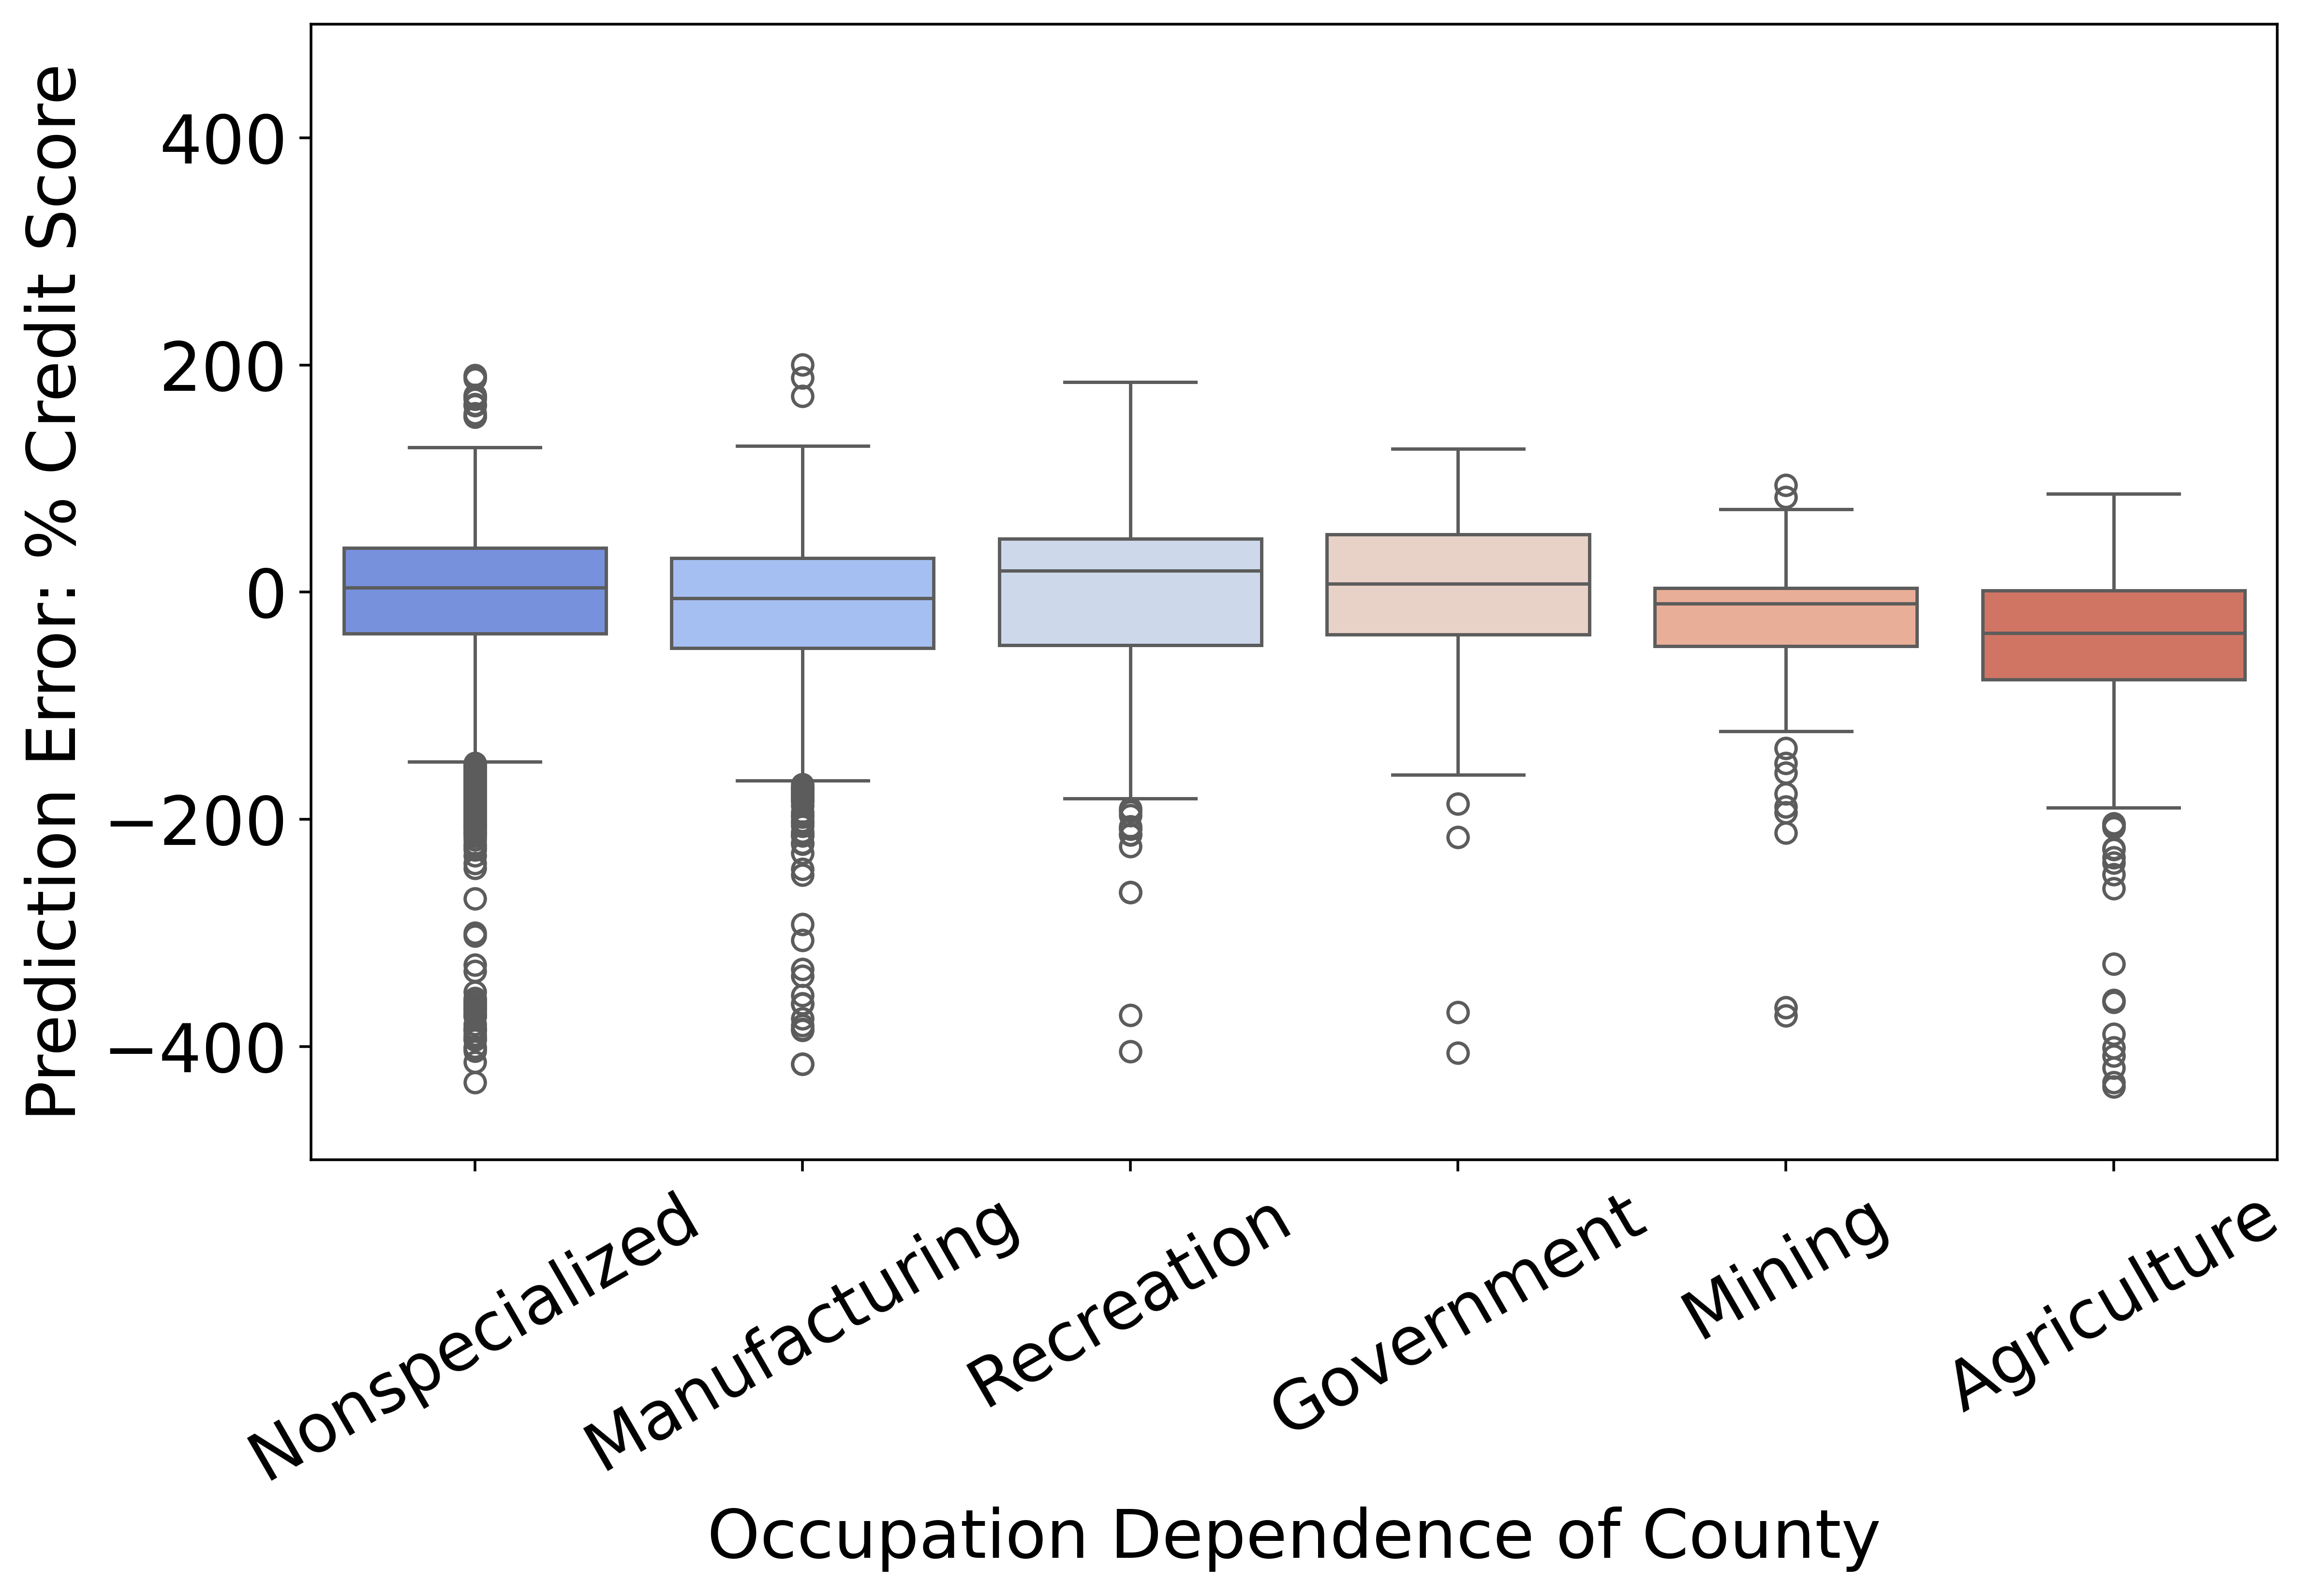

In [153]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged4["OccupationType"] = merged4["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged4, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % Credit Score')

plt.ylim(-500, 500)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [154]:
group_stats = merged4.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture  -49.783030
1      Government   -3.785427
2   Manufacturing  -21.465284
3          Mining  -30.415472
4  Nonspecialized  -13.768865
5      Recreation   -8.839751


In [155]:
merged4 = merged4.dropna(subset=["Value", "Difference"])
print(merged4["Value"].value_counts(dropna=False))


Value
0.0    1577
3.0     706
1.0     354
5.0     265
4.0     146
2.0      89
Name: count, dtype: int64


In [156]:
from scipy.stats import f_oneway

occ_groups = [
    merged4.loc[merged4["Value"] == cat, "Difference"]
    for cat in sorted(merged4["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 13.101, p-value: 0.0000


In [157]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged4["Difference"],
    groups=merged4["Value"],
    alpha=0.05
)
print(tukey)


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   0.0    1.0 -36.0142    0.0 -49.9999 -22.0284   True
   0.0    2.0 -16.6466 0.4451 -42.5549   9.2617  False
   0.0    3.0  -7.6964 0.3209 -18.4647   3.0719  False
   0.0    4.0   9.9834 0.7369 -10.5879  30.5548  False
   0.0    5.0   4.9291 0.9489 -10.8586  20.7168  False
   1.0    2.0  19.3676 0.3667  -8.8304  47.5655  False
   1.0    3.0  28.3177    0.0   12.831  43.8045   True
   1.0    4.0  45.9976    0.0  22.6082   69.387   True
   1.0    5.0  40.9433    0.0  21.6266    60.26   True
   2.0    3.0   8.9502 0.9321 -17.7982  35.6986  False
   2.0    4.0    26.63 0.1655  -5.3497  58.6098  False
   2.0    5.0  21.5757 0.2813   -7.558  50.7094  False
   3.0    4.0  17.6799 0.1816    -3.94  39.2997  False
   3.0    5.0  12.6255 0.2867   -4.506  29.7571  False
   4.0    5.0  -5.0543 0.9918 -29.5638  19.4551  False
----------

#Credit Score llama 3.3 70b

In [158]:
model3 = pd.read_csv('/content/cs_merged_data_llama-3.3-70b-instruct.csv')

In [159]:
merged3 = model3.merge(filt_df, on="county_fips", how="left")

merged3 = merged3.dropna(subset=["county"])

merged3.head()

,county_fips,county,estimate,credit_score,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1017,"Chambers County, AL",624.0,636.839678,-12.839678,AL,Chambers County,0.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1009,"Blount County, AL",624.0,661.909095,-37.909095,AL,Blount County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1021,"Chilton County, AL",624.0,649.721974,-25.721974,AL,Chilton County,1.0,Industry_Dependence_2025,3.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1003,"Baldwin County, AL",657.0,667.065871,-10.065871,AL,Baldwin County,1.0,Industry_Dependence_2025,5.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1001,"Autauga County, AL",682.0,656.947200,25.052800,AL,Autauga County,1.0,Industry_Dependence_2025,0.0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_1057/2863943735.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged3, palette="coolwarm")


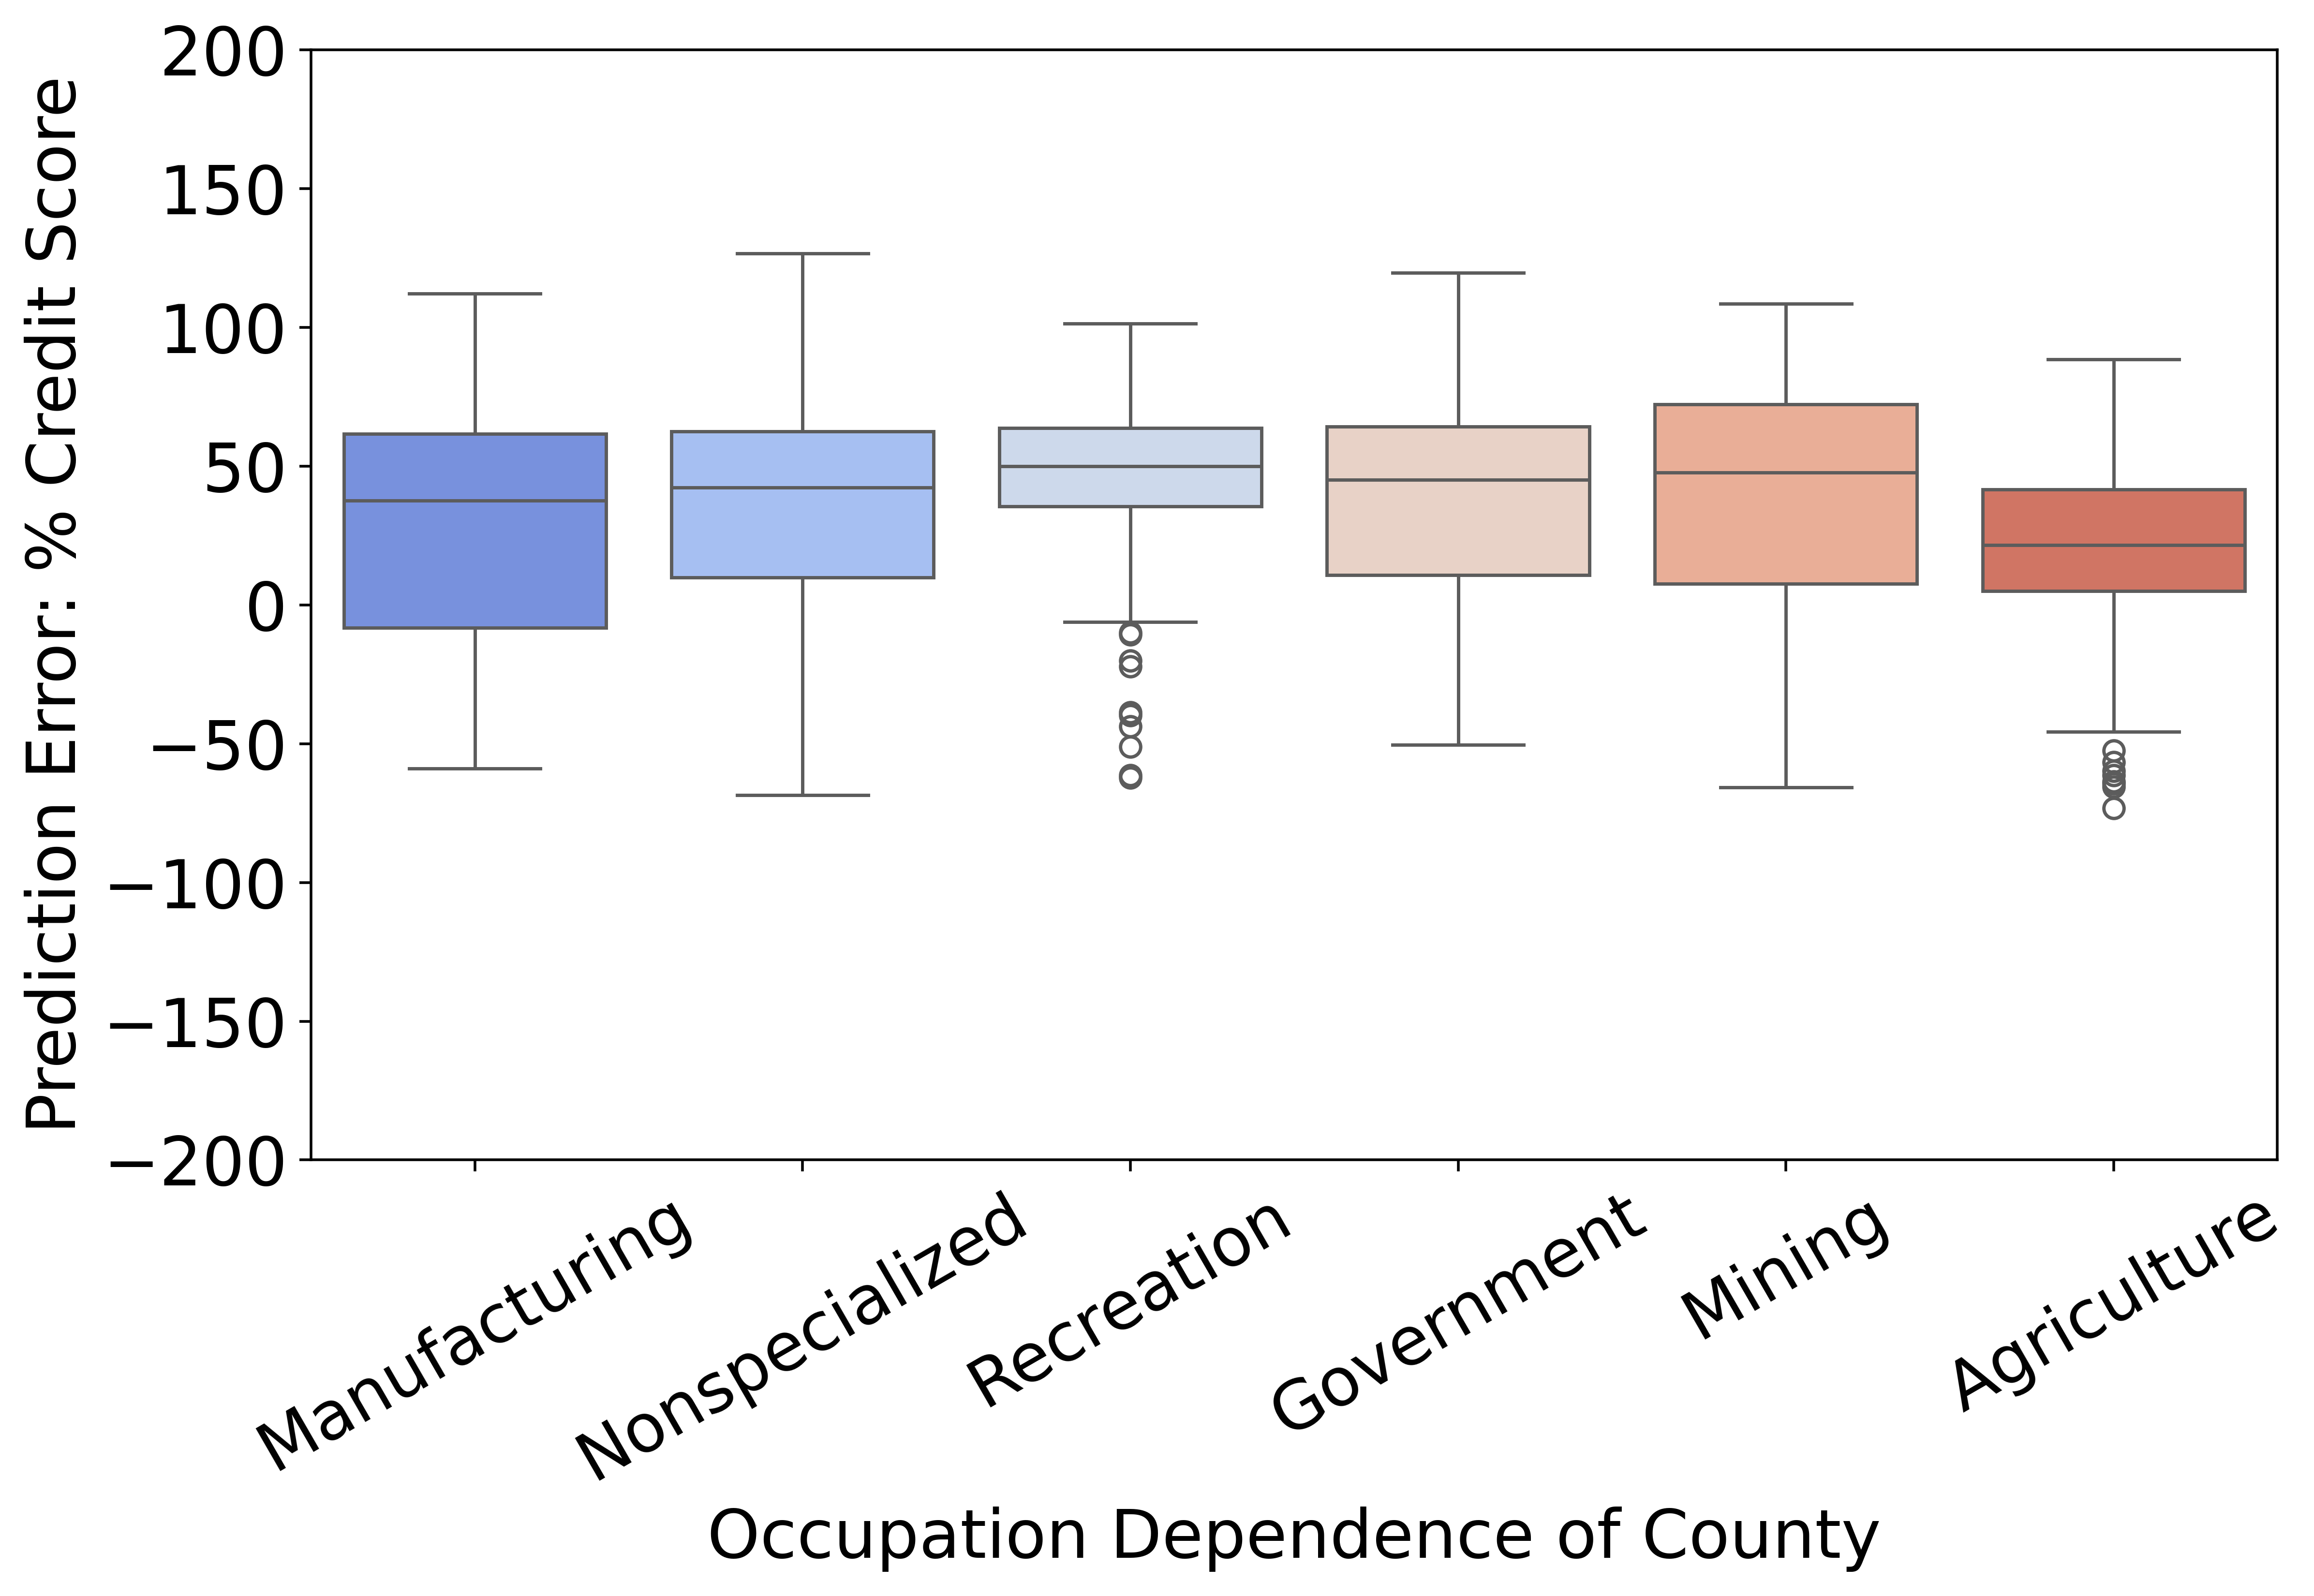

In [160]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged3["OccupationType"] = merged3["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged3, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % Credit Score')

plt.ylim(-200, 200)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [161]:
group_stats = merged3.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture   21.406235
1      Government   37.162518
2   Manufacturing   29.160411
3          Mining   37.584528
4  Nonspecialized   33.755182
5      Recreation   47.624400


In [162]:
merged3 = merged3.dropna(subset=["Value", "Difference"])
print(merged["Value"].value_counts(dropna=False))


Value
0.0    1577
3.0     706
1.0     354
5.0     265
4.0     146
2.0      89
Name: count, dtype: int64


In [163]:
from scipy.stats import f_oneway

occ_groups = [
    merged3.loc[merged3["Value"] == cat, "Difference"]
    for cat in sorted(merged3["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 17.335, p-value: 0.0000


In [164]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged3["Difference"],
    groups=merged3["Value"],
    alpha=0.05
)
print(tukey)


 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
   0.0    1.0 -12.3489    0.0 -18.5837 -6.1142   True
   0.0    2.0   3.8293 0.9346  -7.7203  15.379  False
   0.0    3.0  -4.5948 0.0698  -9.3952  0.2056  False
   0.0    4.0   3.4073 0.8973  -5.7632 12.5778  False
   0.0    5.0  13.8692    0.0   6.8312 20.9072   True
   1.0    2.0  16.1783 0.0034   3.6079 28.7487   True
   1.0    3.0   7.7542 0.0173   0.8503  14.658   True
   1.0    4.0  15.7563 0.0002   5.3295 26.1831   True
   1.0    5.0  26.2182    0.0   17.607 34.8294   True
   2.0    3.0  -8.4241 0.3341 -20.3483  3.5001  False
   2.0    4.0   -0.422    1.0 -14.6783 13.8343  False
   2.0    5.0  10.0399 0.2359  -2.9477 23.0274  False
   3.0    4.0   8.0021 0.1681  -1.6358   17.64  False
   3.0    5.0   18.464    0.0  10.8269 26.1011   True
   4.0    5.0  10.4619 0.0697  -0.4642  21.388  False
----------------------------